In [1]:
%pip install -q -U langgraph

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.0/256.0 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.4/162.4 kB 4.7 MB/s eta 0:00:00


In [2]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.types import interrupt, Command

print("LangGraph imports successful.")

LangGraph imports successful.


In [3]:
class AgentState(TypedDict, total=False):
    user_input: str
    classification: str
    needs_human_review: bool
    route_decision: str
    response: str
    human_feedback: str


def classify_node(state: AgentState):
    text = state["user_input"].lower()

    review_keywords = ["medical", "legal", "financial", "high risk"]

    needs_review = any(word in text for word in review_keywords)

    return {
        "classification": "needs_review" if needs_review else "general",
        "needs_human_review": needs_review
    }


print("Classification node defined.")

Classification node defined.


In [4]:
def route_node(state: AgentState):
    decision = (
        "human_review"
        if state["needs_human_review"]
        else "direct_response"
    )

    return {"route_decision": decision}


def respond_node(state: AgentState):
    if state["needs_human_review"]:
        feedback = interrupt({
            "message": "Human review required.",
            "user_input": state["user_input"],
            "classification": state["classification"],
            "question": "Approve or provide guidance before responding."
        })

        return {
            "human_feedback": str(feedback),
            "response": f"Response prepared using human guidance: {feedback}"
        }

    return {
        "response": (
            f"General response to: {state['user_input']}"
        )
    }


print("Route and respond nodes defined.")

Route and respond nodes defined.


In [5]:
def choose_route(state: AgentState):
    if state["classification"] == "needs_review":
        return "route"
    return "respond"


builder = StateGraph(AgentState)

builder.add_node("classify", classify_node)
builder.add_node("route", route_node)
builder.add_node("respond", respond_node)

builder.add_edge(START, "classify")

builder.add_conditional_edges(
    "classify",
    choose_route,
    {
        "route": "route",
        "respond": "respond"
    }
)

builder.add_edge("route", "respond")
builder.add_edge("respond", END)

checkpointer = MemorySaver()
graph = builder.compile(checkpointer=checkpointer)

print("Three-node LangGraph compiled successfully.")
print("Nodes: classify → route → respond")

Three-node LangGraph compiled successfully.
Nodes: classify → route → respond


In [6]:
test_inputs = [
    "Explain machine learning.",
    "How does Python work?",
    "Give me study tips for exams.",
    "Explain neural networks.",
    "Suggest ways to improve my coding skills."
]

for i, user_text in enumerate(test_inputs, start=1):
    result = graph.invoke(
        {"user_input": user_text},
        config={"configurable": {"thread_id": f"test-{i}"}}
    )

    print(f"\nTest {i}: {user_text}")
    print("Classification:", result["classification"])
    print("Route:", "direct response")
    print("Response:", result["response"])


Test 1: Explain machine learning.
Classification: general
Route: direct response
Response: General response to: Explain machine learning.

Test 2: How does Python work?
Classification: general
Route: direct response
Response: General response to: How does Python work?

Test 3: Give me study tips for exams.
Classification: general
Route: direct response
Response: General response to: Give me study tips for exams.

Test 4: Explain neural networks.
Classification: general
Route: direct response
Response: General response to: Explain neural networks.

Test 5: Suggest ways to improve my coding skills.
Classification: general
Route: direct response
Response: General response to: Suggest ways to improve my coding skills.


In [7]:
config = {"configurable": {"thread_id": "human-review-test"}}

paused_result = graph.invoke(
    {"user_input": "I need guidance about a medical decision."},
    config=config
)

print("Graph paused for human review:")
print(paused_result["__interrupt__"])

Graph paused for human review:
[Interrupt(value={'message': 'Human review required.', 'user_input': 'I need guidance about a medical decision.', 'classification': 'needs_review', 'question': 'Approve or provide guidance before responding.'}, id='0546ff2d10f9e7639850a5c6dd346871', response_schema=None)]


In [8]:
human_feedback = input(
    "Human review: enter approval or guidance: "
)

resumed_result = graph.invoke(
    Command(resume=human_feedback),
    config=config
)

print("\nGraph resumed successfully.")
print("Human feedback:", resumed_result["human_feedback"])
print("Final response:", resumed_result["response"])

Human review: enter approval or guidance: Approved. Provide general information and recommend consulting a qualified medical professional.

Graph resumed successfully.
Human feedback: Approved. Provide general information and recommend consulting a qualified medical professional.
Final response: Response prepared using human guidance: Approved. Provide general information and recommend consulting a qualified medical professional.


In [9]:
general_result = graph.invoke(
    {"user_input": "Explain artificial intelligence."},
    config={"configurable": {"thread_id": "routing-general"}}
)

review_result = graph.invoke(
    {"user_input": "I need help with a legal decision."},
    config={"configurable": {"thread_id": "routing-review"}}
)

assert general_result["classification"] == "general"
assert review_result["classification"] == "needs_review"
assert review_result["route_decision"] == "human_review"

print("General routing: PASS")
print("Human-review routing: PASS")
print("Conditional routing verified.")

General routing: PASS
Human-review routing: PASS
Conditional routing verified.


In [10]:
print("LangGraph workflow:")
print("START → classify")
print("classify → respond (general)")
print("classify → route → respond (needs review)")
print("respond → END")

LangGraph workflow:
START → classify
classify → respond (general)
classify → route → respond (needs review)
respond → END


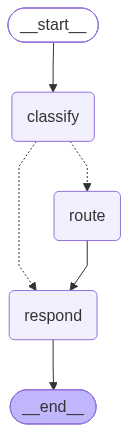

In [12]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [11]:
from pathlib import Path

report = f"""# W10D1: LangGraph — Stateful Agent Graphs

## Implementation
- Three nodes: classify, route, respond
- Conditional routing based on classification
- Human-in-the-loop interrupt and resume
- In-memory checkpointing with thread IDs

## Testing
- General input tests: {len(test_inputs)}
- Human-review interrupt: tested
- Human feedback and resume: tested
- Conditional routing assertions: passed
"""

Path("W10D1_LangGraph_Report.md").write_text(
    report, encoding="utf-8"
)

print("W10D1 report saved.")

W10D1 report saved.
